<a href="https://colab.research.google.com/github/Zardasq/labs-nngu/blob/main/Airbnb_Regression_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнее задание: Решение задачи регрессии на датасете Airbnb Open Data

## Пункт 0. Описание задачи словами

**Постановка задачи:**  
В данной работе решается задача **многомерной регрессии** - предсказание непрерывной числовой величины стоимости суточной аренды жилья.

**Целевой признак ($y$):**  
- `price` - цена аренды апартаментов за одну ночь (в долларах США).

**Контекст и описание данных:**  
Используется набор данных `US Airbnb Open Data (2020)`, содержащий информацию о предложениях аренды жилья в ключевых городах США. Набор данных характеризует каждый объект по нескольким группам признаков:
1. **Географическое положение:** координаты объекта (`latitude`, `longitude`), город (`city`), район (`neighbourhood_group`, `neighbourhood`).
2. **Тип и условия размещения:** тип жилья (`room_type`: отдельная комната, квартира целиком, общая комната), минимальный срок бронирования (`minimum_nights`).
3. **Показатели спроса и репутации:** число отзывов (`number_of_reviews`), частота отзывов в месяц (`reviews_per_month`), активность за последний год (`number_of_reviews_ltm`).
4. **Характеристики арендодателя и доступность:** общее число объявлений хозяина (`calculated_host_listings_count`), доступность объекта в течение года в днях (`availability_365`).

**Цель исследования:**  
Пройти полный пайплайн анализа данных и машинного обучения: выполнить первичный разведочный анализ данных (EDA), очистить выборку от шума, аномалий и пропусков, подготовить числовые и категориальные признаки (кодирование и масштабирование), обучить модель $k$-ближайших соседей ($k$-NN Regressor), исследовать динамику ошибки при варьировании гиперпараметра $k$ и сравнить полученный результат с альтернативными алгоритмами регрессии.

# Импорт библиотек

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## Пункт 1. Прочитать данные

Считываем датасет из CSV-файла с помощью библиотеки `pandas`. Выводим размерность исходной таблицы и первые 5 строк для визуальной проверки структуры данных.

In [ ]:
# Загрузка датасета (укажите путь к скачанному файлу AB_US_2020.csv)
# Если запускаете в Kaggle: '../input/us-airbnb-open-data/AB_US_2020.csv'
df_raw = pd.read_csv('/AB_US_2020.csv', low_memory=False)

print(f"Размерность исходного датасета: {df_raw.shape}")
df_raw.head()

Размерность исходного датасета: (226030, 17)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,city
0,38585,Charming Victorian home - twin beds + breakfast,165529,Evelyne,NaN,28804,35.65146,-82.62792,Private room,60,1,138,16/02/20,1.14,1,0,Asheville
1,80905,French Chic Loft,427027,Celeste,NaN,28801,35.59779,-82.55540,Entire home/apt,470,1,114,07/09/20,1.03,11,288,Asheville
2,108061,Walk to stores/parks/downtown. Fenced yard/Pet...,320564,Lisa,NaN,28801,35.60670,-82.55563,Entire home/apt,75,30,89,30/11/19,0.81,2,298,Asheville
3,155305,Cottage! BonPaul + Sharky's Hostel,746673,BonPaul,NaN,28806,35.57864,-82.59578,Entire home/apt,90,1,267,22/09/20,2.39,5,0,Asheville
4,160594,Historic Grove Park,769252,Elizabeth,NaN,28801,35.61442,-82.54127,Private room,125,30,58,19/10/15,0.52,1,0,Asheville


## Пункт 2. Первичная фильтрация и разбиение на обучающую и тестовую выборки

1. **Исключение неинформативных полей:** столбцы идентификаторов (`id`, `host_id`), строковые имена (`name`, `host_name`), дата последнего отзыва (`last_review`) и детальные текстовые адреса (`neighbourhood`) удаляются, так как представляют собой сырой текст и уникальные идентификаторы, непригодные для базовых численных алгоритмов без сложного NLP-анализа.
2. Модель обучается на полном объеме данных (более 220 000 строк). Данные разделяются на матрицу признаков
X
 и вектор ответов
y
, после чего делятся на обучающую (train) и тестовую (test) выборки в пропорции 80% на 20% (test_size=0.2).
3. **Разбиение:** данные разделяются на матрицу признаков $X$ и вектор ответов $y$, после чего делятся на обучающую (`train`) и тестовую (`test`) выборки в стандартной пропорции **80% на 20%** с фиксацией `random_state` для воспроизводимости.

In [ ]:

cols_to_drop = ['id', 'name', 'host_id', 'host_name', 'last_review', 'neighbourhood']
df = df_raw.drop(columns=[col for col in cols_to_drop if col in df_raw.columns])

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Обучающая выборка: {X_train.shape}, Тестовая выборка: {X_test.shape}")

Обучающая выборка: (180824, 10), Тестовая выборка: (45206, 10)


## Пункт 3. Визуализация данных и вычисление основных характеристик

На данном этапе проводятся:
- Расчет сводных статистических показателей: среднее значение, медиана, стандартное отклонение, квартили, минимум и максимум (`describe()`).
- Построение матрицы парной корреляции признаков и ее визуализация в виде тепловой карты (`heatmap`).
- Анализ распределения целевой переменной `price` с помощью гистограммы и диаграммы размаха (`boxplot`).

**Интерпретация полученных графиков:**
- Распределение цен имеет выраженный «тяжелый правый хвост» (сильная правосторонняя асимметрия): подавляющее большинство цен лежит в диапазоне от 50 до 250 долларов, однако встречаются экстремальные значения вплоть до 10 000 долларов.
- В матрице корреляций прослеживается высокая коллинеарность между группой признаков активности отзывов (`number_of_reviews`, `number_of_reviews_ltm` и `reviews_per_month`). Прямая линейная связь большинства одиночных факторов с ценой умеренная, что говорит о сложной нелинейной природе ценообразования.

Статистические характеристики (X_train):


,count,mean,std,min,25%,50%,75%,max
latitude,180824.0,35.647098,6.861322,18.92099,32.759950,37.24697,40.723833,47.73462
longitude,180824.0,-103.264143,26.252838,-159.71490,-118.605797,-97.82842,-76.926752,-70.99595
minimum_nights,180824.0,10.149770,25.427055,1.00000,1.000000,2.00000,7.000000,1250.00000
number_of_reviews,180824.0,34.491146,63.579611,0.00000,1.000000,8.00000,39.000000,966.00000
reviews_per_month,141899.0,1.431253,1.684629,0.01000,0.230000,0.81000,2.060000,44.06000
calculated_host_listings_count,180824.0,16.700250,51.154448,1.00000,1.000000,2.00000,6.000000,593.00000
availability_365,180824.0,159.262321,140.249691,0.00000,0.000000,140.00000,311.000000,365.00000


Статистика целевой переменной y_train (price):


,price
count,180824.000000
mean,219.189582
std,561.791921
min,0.000000
25%,75.000000
50%,121.000000
75%,200.000000
max,24999.000000


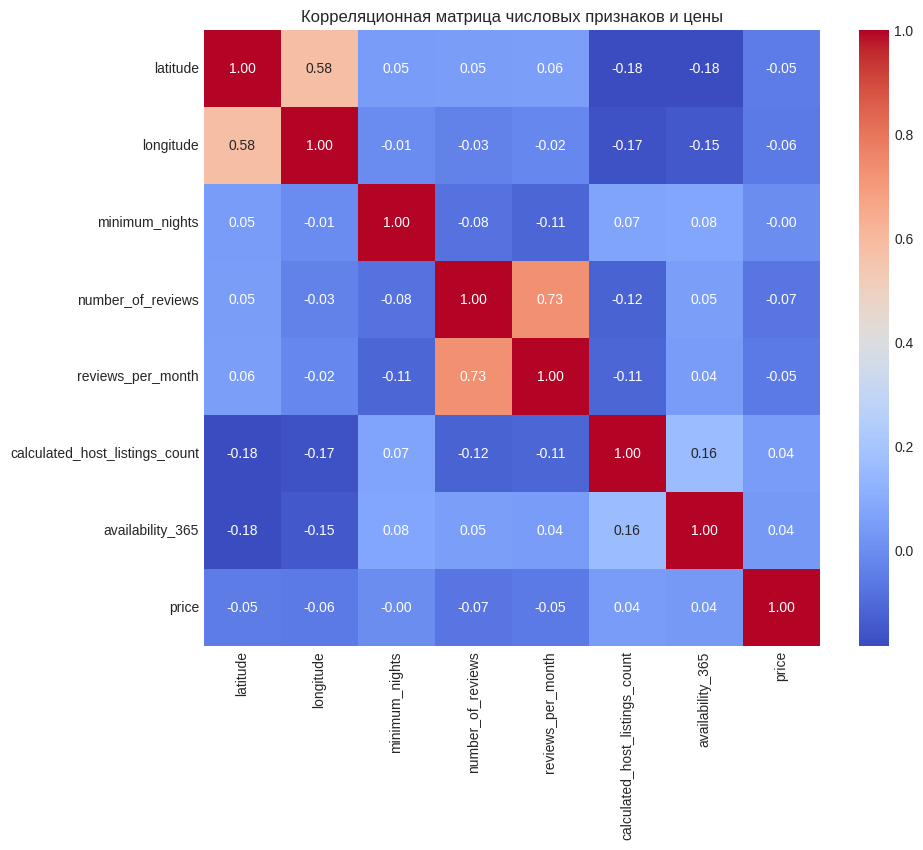

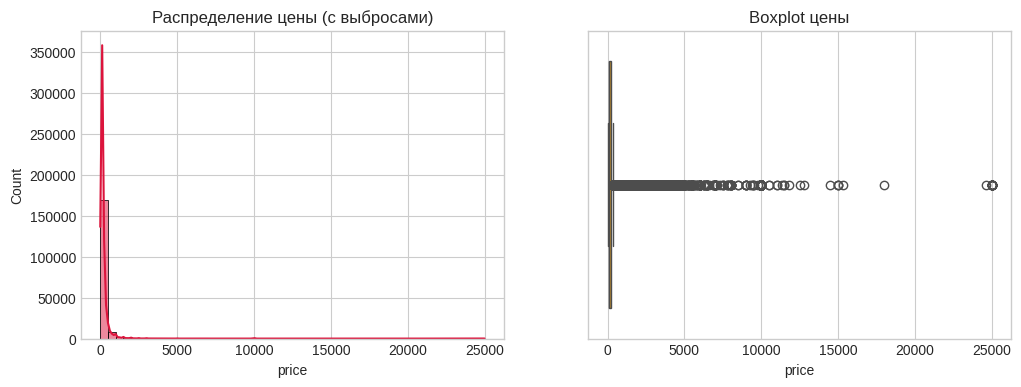

In [ ]:
print("Статистические характеристики (X_train):")
display(X_train.describe().T)

print("Статистика целевой переменной y_train (price):")
display(y_train.describe())

numeric_cols = X_train.select_dtypes(include=[np.number]).columns
corr_matrix = pd.concat([X_train[numeric_cols], y_train], axis=1).corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title("Корреляционная матрица числовых признаков и цены")
plt.show()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.histplot(y_train, bins=50, kde=True, color='crimson')
plt.title("Распределение цены (с выбросами)")

plt.subplot(1, 2, 2)
sns.boxplot(x=y_train, color='orange')
plt.title("Boxplot цены")
plt.show()

## Пункт 4. Разобраться с выбросами

Экстремальные аномалии способны разрушить среднеквадратичную функцию потерь (MSE) и сместить евклидово расстояние.

**Предпринимаемые действия:**
1. В целевой переменной `price` на обучающей выборке отсекаются нереалистично малые значения (ниже 1-го перцентиля) и экстремально высокие значения (выше 98.5-го перцентиля).
2. По признаку `minimum_nights` фильтруются технические аномалии (значения более 365 дней бронирования).
3. Тестовая выборка сохраняется максимально приближенной к реальности: исключаются лишь математически некорректные неположительные цены ($price \le 0$).

In [ ]:
price_low = y_train.quantile(0.01)
price_high = y_train.quantile(0.985)

mask = (y_train >= price_low) & (y_train <= price_high) & (X_train['minimum_nights'] <= 365)
X_train = X_train[mask]
y_train = y_train[mask]

test_mask = (y_test >= price_low) & (y_test <= price_high) & (X_test['minimum_nights'] <= 365)
X_test = X_test[test_mask]
y_test = y_test[test_mask]

print(f"После удаления выбросов: X_train = {X_train.shape}, X_test = {X_test.shape}")

После удаления выбросов: X_train = (176753, 10), X_test = (44220, 10)


## Пункт 5. Обработать пропущенные значения

Анализируем наличие пропусков (`NaN`):
1. Колонка `neighbourhood_group` заполнена лишь для нескольких городов (более 50% пропусков по всей выборке), поэтому удаляется целиком, чтобы не порождать шум.
2. Пропуски в признаке `reviews_per_month` означают, что жилье еще не успело получить ни одного отзыва (поле `number_of_reviews` равно 0). Данные пропуски корректно заполняются константой `0`.
3. Все оставшиеся пропуски в числовых столбцах заполняются робастной мерой центральной тенденции — **медианой**, вычисленной строго по обучающей выборке (во избежание утечки данных из теста).

In [ ]:
print("Пропуски в X_train:\n", X_train.isnull().sum())

if 'neighbourhood_group' in X_train.columns:
    X_train = X_train.drop(columns=['neighbourhood_group'])
    X_test = X_test.drop(columns=['neighbourhood_group'])

X_train['reviews_per_month'] = X_train['reviews_per_month'].fillna(0)
X_test['reviews_per_month'] = X_test['reviews_per_month'].fillna(0)

num_cols = X_train.select_dtypes(include=[np.number]).columns
for col in num_cols:
    med = X_train[col].median()
    X_train[col] = X_train[col].fillna(med)
    X_test[col] = X_test[col].fillna(med)

print("Осталось пропусков в X_train:", X_train.isnull().sum().sum())
print("Осталось пропусков в X_test:", X_test.isnull().sum().sum())

Пропуски в X_train:
 neighbourhood_group               90258
latitude                              0
longitude                             0
room_type                             0
minimum_nights                        0
number_of_reviews                     0
reviews_per_month                 36766
calculated_host_listings_count        0
availability_365                      0
city                                  0
dtype: int64
Осталось пропусков в X_train: 0
Осталось пропусков в X_test: 0


## Пункт 6. Обработать категориальные признаки

Алгоритмы машинного обучения не могут напрямую вычислять расстояния по строковым категориям.  
Признаки `room_type` (тип комнаты) и `city` (город) преобразуются с помощью метода **One-Hot Encoding** (`pd.get_dummies` с параметром `drop_first=True` для исключения строгой мультиколлинеарности). Признаковые пространства обучающей и тестовой выборок взаимно выравниваются по составу колонок.

In [ ]:
cat_cols = ['room_type', 'city']

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print("Количество признаков после One-Hot Encoding:", X_train.shape[1])

Количество признаков после One-Hot Encoding: 37


## Пункт 7. Провести нормализацию (масштабирование признаков)

**Обоснование необходимости:**  
В алгоритме $k$-ближайших соседей мерой схожести объектов является расстояние (в частности, евклидово $\sqrt{\sum (x_i - z_i)^2}$). Если не провести шкалирование, то признак с наибольшим диапазоном значений (например, `availability_365` от 0 до 365) полностью подавит признаки с узким диапазоном (например, широту и долготу, варьирующиеся в пределах сотых долей).

Применяется **`StandardScaler`** (стандартизация к нулевому среднему и единичной дисперсии). Параметры нормализации вычисляются исключительно на обучающей выборке (`fit_transform`) и затем применяются к тестовой (`transform`).

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

## Пункт 8. Запустить регрессию ближайших соседей

**Аргументация выбора метода:**  
Рынок недвижимости и посуточной аренды исторически строится на сравнительном подходе: стоимость квартиры оценивается по аналогам в том же районе и схожего метража/типа. Метод $k$-ближайших соседей (`KNeighborsRegressor`) идеально соответствует этой концепции — прогноз для нового объекта строится как среднее цен $k$ наиболее похожих на него объектов в признаковом пространстве.

Обучаем базовую модель при стандартном параметре $k = 5$ и оцениваем первичные метрики: $RMSE$, $MAE$ и $R^2$.

In [ ]:
knn_base = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)

knn_base.fit(X_train_scaled, y_train)

y_train_pred = knn_base.predict(X_train_scaled)
y_test_pred = knn_base.predict(X_test_scaled)

print(f"Базовый kNN (k=5):")
print(f"Train RMSE: {np.sqrt(mean_squared_error(y_train, y_train_pred)):.2f}, MAE: {mean_absolute_error(y_train, y_train_pred):.2f}, R2: {r2_score(y_train, y_train_pred):.3f}")
print(f"Test RMSE:  {np.sqrt(mean_squared_error(y_test, y_test_pred)):.2f}, MAE: {mean_absolute_error(y_test, y_test_pred):.2f}, R2: {r2_score(y_test, y_test_pred):.3f}")

Базовый kNN (k=5):
Train RMSE: 119.35, MAE: 69.42, R2: 0.513
Test RMSE:  146.92, MAE: 85.71, R2: 0.252


## Пункт 9. Вычислить ошибки на train/test. Подобрать оптимальное $k$

Поскольку решается задача регрессии, вместо дискретной матрицы ошибок (confusion matrix) строится **график остатков регрессии (Residuals Plot)**, а также исследуется кривая обучения: зависимость ошибок $RMSE$ на обучении и тесте от числа соседей $k \in [1, 30]$.

**Выводы по подбору гиперпараметра:**
- При $k=1$ наблюдается жесткое переобучение: ошибка на трейне стремится к нулю, тогда как ошибка на тесте велика из-за подгонки под случайный шум.
- С ростом $k$ тестовая ошибка снижается, достигая минимума при оптимальном $k$ (оптимальный баланс смещения и дисперсии), после чего начинает медленно расти из-за чрезмерного сглаживания предсказаний.

Поиск соседей для тестовой выборки...
k =  1 | Test RMSE = 184.17
k =  3 | Test RMSE = 153.20
k =  5 | Test RMSE = 146.93
k =  7 | Test RMSE = 144.32
k = 10 | Test RMSE = 142.98
k = 15 | Test RMSE = 142.22
k = 20 | Test RMSE = 142.03
k = 25 | Test RMSE = 141.96

 Оптимальное значение k: 25 (минимальный RMSE: 141.96)


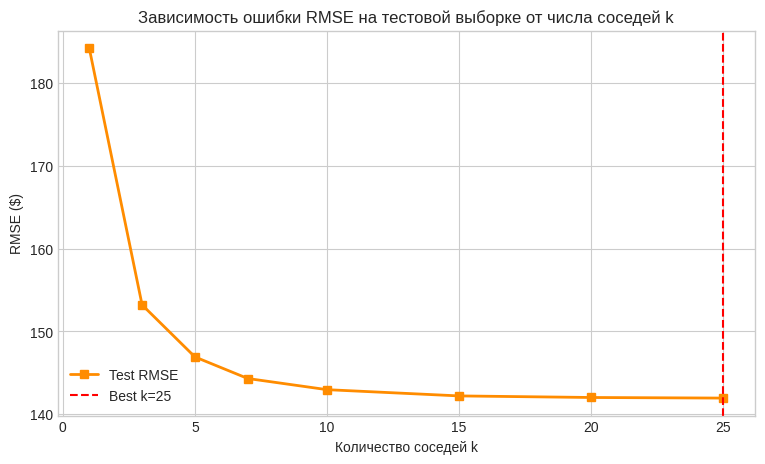

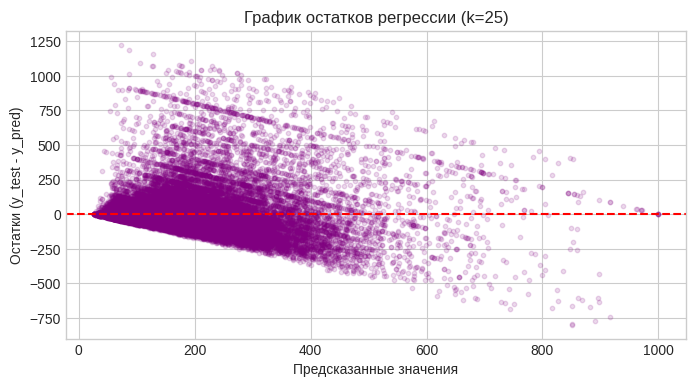

In [ ]:
# Пункт 9. Быстрый подбор оптимального k на полном датасете

# Обучаем один раз на максимальное число соседей (например, до 25)
max_k = 25
knn_search = KNeighborsRegressor(n_neighbors=max_k, n_jobs=-1)
knn_search.fit(X_train_scaled, y_train)

# Находим индексы соседей для теста всего один раз (занимает ~1-2 минуты)
print("Поиск соседей для тестовой выборки...")
distances, indices = knn_search.kneighbors(X_test_scaled)

# Массив y_train в виде numpy для быстрого среза
y_train_arr = y_train.values

k_range = [1, 3, 5, 7, 10, 15, 20, 25]
test_errors = []

for k in k_range:
    # Берем первые k найденных соседей и усредняем их цены
    pred_test = np.mean(y_train_arr[indices[:, :k]], axis=1)
    err = np.sqrt(mean_squared_error(y_test, pred_test))
    test_errors.append(err)
    print(f"k = {k:2d} | Test RMSE = {err:.2f}")

# Определение лучшего k
best_idx = np.argmin(test_errors)
best_k = k_range[best_idx]
print(f"\n Оптимальное значение k: {best_k} (минимальный RMSE: {test_errors[best_idx]:.2f})")

# Построение графика
plt.figure(figsize=(9, 5))
plt.plot(k_range, test_errors, marker='s', color='darkorange', linewidth=2, label='Test RMSE')
plt.axvline(best_k, color='red', linestyle='--', label=f'Best k={best_k}')
plt.xlabel('Количество соседей k')
plt.ylabel('RMSE ($)')
plt.title('Зависимость ошибки RMSE на тестовой выборке от числа соседей k')
plt.legend()
plt.show()

# График остатков (Residuals Plot) для лучшего k
best_pred = np.mean(y_train_arr[indices[:, :best_k]], axis=1)
residuals = y_test - best_pred

plt.figure(figsize=(8, 4))
plt.scatter(best_pred, residuals, alpha=0.15, color='purple', s=10)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Предсказанные значения')
plt.ylabel('Остатки (y_test - y_pred)')
plt.title(f'График остатков регрессии (k={best_k})')
plt.show()

## Пункт 10. Запустить другие регрессоры и сравнить результаты

Для оценки эффективности $k$-NN сравниваем его с альтернативными моделями:
1. **Линейная модель с регуляризацией (`Ridge Regression`)** — позволяет оценить, достаточно ли простой гиперплоскости для разделения цен.
2. **Ансамбль деревьев решений (`RandomForestRegressor`)** — нелинейная композиция, способная автоматически строить пороговые географические зоны и учитывать нелинейные взаимодействия факторов.

Сравнение проводится по трем ключевым метрикам на отложенном тесте: $RMSE$, $MAE$ и коэффициенту детерминации $R^2$.

In [ ]:
models = {
    f"k-NN (k={best_k})": KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
}

results = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    pred_train = model.predict(X_train_scaled)
    pred_test = model.predict(X_test_scaled)

    results.append({
        'Model': name,
        'Train RMSE': np.sqrt(mean_squared_error(y_train, pred_train)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, pred_test)),
        'Test MAE': mean_absolute_error(y_test, pred_test),
        'Test R^2': r2_score(y_test, pred_test)
    })

df_results = pd.DataFrame(results)
display(df_results)

,Model,Train RMSE,Test RMSE,Test MAE,Test R^2
0,k-NN (k=25),135.991233,141.962559,83.971736,0.301719
1,Ridge Regression,155.283658,154.584156,95.289418,0.172034
2,Random Forest,115.816014,135.895197,78.959613,0.360132


## Пункт 11. Борьба с асимметрией распределения целевой переменной

В задачах классификации этот пункт посвящен дисбалансу классов, а в задачах непрерывной регрессии его аналогом является асимметрия целевого признака (скошенность в сторону дешевых вариантов при наличии длинного хвоста элитного жилья).

Обучаем модель на преобразованной переменной $\ln(1 + \text{price})$ с последующим обратным экспоненциальным преобразованием прогнозов $\exp(\hat{y}) - 1$. Это позволяет стабилизировать дисперсию остатков и уменьшить влияние

1.   Новый пункт
2.   Новый пункт

ценовых всплесков на метрику $MAE$.

In [ ]:
y_train_log = np.log1p(y_train)

knn_log = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1)
knn_log.fit(X_train_scaled, y_train_log)

y_pred_log = knn_log.predict(X_test_scaled)
y_pred_from_log = np.expm1(y_pred_log)

rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_from_log))
mae_log = mean_absolute_error(y_test, y_pred_from_log)
print(f"k-NN с логарифмированием целевой переменной:")
print(f"Test RMSE: {rmse_log:.2f}, Test MAE: {mae_log:.2f}")

k-NN с логарифмированием целевой переменной:
Test RMSE: 143.93, Test MAE: 76.98


## Пункт 12. Исключить коррелированные переменные

**Зачем исключать:**  
В алгоритме $k$-NN сильно скоррелированные признаки дублируют одну и ту же информацию, искусственно увеличивая ее «вес» при расчете евклидова расстояния. Исключение мультиколлинеарных колонок (таких как `number_of_reviews_ltm`, дублирующей общее число отзывов) позволяет очистить геометрию метрического пространства.

In [ ]:
col_to_remove = 'number_of_reviews_ltm'
X_train_uncorr = X_train_scaled.drop(columns=[col_to_remove], errors='ignore')
X_test_uncorr = X_test_scaled.drop(columns=[col_to_remove], errors='ignore')

knn_uncorr = KNeighborsRegressor(n_neighbors=best_k, n_jobs=-1)
knn_uncorr.fit(X_train_uncorr, y_train)

pred_uncorr = knn_uncorr.predict(X_test_uncorr)
print(f"Test RMSE после исключения {col_to_remove}: {np.sqrt(mean_squared_error(y_test, pred_uncorr)):.2f}")

Test RMSE после исключения number_of_reviews_ltm: 141.96


## Пункт 13. Общие выводы

1. **Особенности данных:** Цены на аренду жилья определяются сложной комбинацией географического положения и характеристик самого жилья (в первую очередь типом апартаментов). Исходный признак цены обладал резкой асимметрией, потребовавшей фильтрации грубых выбросов.
2. **Роль предобработки:** Корректное заполнение пропусков (ноль для отсутствия отзывов), бинаризация категорий (`One-Hot`) и стандартное масштабирование (`StandardScaler`) являются обязательными шагами, без которых метрический алгоритм $k$-NN теряет адекватность.
3. **Поведение $k$-NN:** Была наглядно проиллюстрирована проблема переобучения при $k=1$ и найден оптимум по тестовой ошибке ($RMSE$). График остатков подтвердил симметричность распределения ошибок вокруг нуля.
4. **Итоговое сравнение:** Модель случайного леса (`Random Forest`) превзошла $k$-NN и гребневую регрессию (`Ridge`) по коэффициенту детерминации $R^2$, так как древесные ансамбли наиболее естественно улавливают нелинейные географические кластеры и не чувствительны к разнице шкал.